<a href="https://colab.research.google.com/github/carlcabalsi/Student-Dropout-Risk-Early-Warning-System/blob/main/Carlito_Cabalsi_Complete_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Student Dropout Risk Using Academic, Mental Health, and Lifestyle Indicators: An Explainable Machine Learning Approach

## Business Problem

Student dropout remains a major challenge for educational institutions. Students experiencing poor academic performance, burnout, psychological stress, financial difficulties, and low motivation are more likely to leave their studies before completing their education.

Educational institutions need an early warning system capable of identifying students at risk of dropping out so that interventions such as counseling, academic support, mentoring, and financial assistance can be provided before withdrawal occurs.

## Data Science Problem

Develop a machine learning classification model that predicts student dropout risk using academic performance, mental health indicators, financial stress factors, and lifestyle-related variables.

The prediction will assist educational institutions in identifying at-risk students and prioritizing intervention efforts.

## Task Type

This project is a supervised machine learning classification problem.

Target Variable:

Dropout_Risk

Classes:

- Yes = At Risk of Dropping Out
- No = Not At Risk of Dropping Out

## Dataset Overview

This dataset is sourced from Kaggle, published by Harpartap Singh, and contains data focused on analyzing student burnout indicators and dropout risk factors. The dataset contains student demographic, academic, lifestyle, financial, and psychological information.

Academic Features:
- Attendance_Percent
- Study_Hours_Per_Day
- Previous_GPA
- Backlogs

Mental Health Features:
- Stress_Level
- Anxiety_Score
- Burnout_Level
- Motivation_Score

Lifestyle Features:
- Sleep_Hours
- Screen_Time_Hours
- Exercise_Freq_Per_Week
- Social_Activity_Score

Financial Features:
- Family_Income_Bracket
- Financial_Stress_Score

Support Features:
- Family_Support_Score
- Counseling_Access

Target:
- Dropout_Risk

## Success Metrics

Primary Metrics

- F1 Score
- Recall
- ROC-AUC

Secondary Metrics

- Accuracy
- Precision
- Confusion Matrix

Recall is important because failing to identify students who are truly at risk may prevent timely intervention.

## Business KPIs

- Early identification of at-risk students
- Improved intervention effectiveness
- Reduced dropout rates
- Increased retention rates
- Improved student well-being support

## Candidate Models

The following models will be evaluated:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. XGBoost

The best model will be selected based on F1 Score, Recall, and ROC-AUC performance.

In [ ]:
import pandas as pd

# Load the raw student dropout and burnout dataset
df = pd.read_csv("student_burnout_dropout_dataset_2.csv")

# Display the basic dimensions of the loaded dataset
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 800
Columns: 25


In [ ]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Department,Residence_Type,Attendance_Percent,Study_Hours_Per_Day,Previous_GPA,Backlogs,...,Family_Income_Bracket,Financial_Stress_Score,Family_Support_Score,Stress_Level,Anxiety_Score,Motivation_Score,Peer_Pressure_Score,Counseling_Access,Burnout_Level,Dropout_Risk
0,STU00001,23,Female,2,Science,Hostel,93.0,4.1,7.13,2.0,...,Upper-Middle,5.5,10.0,4.0,NaN,7.0,NaN,No,Low,No
1,STU00002,20,Female,4,Engineering,Day Scholar,94.3,0.0,10.00,0.0,...,Low,3.7,4.0,5.5,5.1,9.3,2.8,Yes,Medium,Yes
2,STU00003,24,Male,2,Business,PG/Rented,61.2,2.6,8.02,0.0,...,Middle,4.8,8.1,9.0,5.2,5.7,5.4,No,High,Yes
3,STU00004,21,Female,4,Medicine,Hostel,66.9,3.1,5.34,1.0,...,Lower-Middle,7.0,6.6,2.8,4.2,5.1,3.9,No,High,Yes
4,STU00005,23,Female,1,Engineering,NaN,84.8,2.9,4.45,1.0,...,Lower-Middle,1.3,7.3,0.9,6.4,8.1,5.1,No,Low,No


In [ ]:
df.columns.tolist()

['Student_ID',
 'Age',
 'Gender',
 'Year_of_Study',
 'Department',
 'Residence_Type',
 'Attendance_Percent',
 'Study_Hours_Per_Day',
 'Previous_GPA',
 'Backlogs',
 'Sleep_Hours',
 'Screen_Time_Hours',
 'Exercise_Freq_Per_Week',
 'Social_Activity_Score',
 'Part_Time_Job',
 'Family_Income_Bracket',
 'Financial_Stress_Score',
 'Family_Support_Score',
 'Stress_Level',
 'Anxiety_Score',
 'Motivation_Score',
 'Peer_Pressure_Score',
 'Counseling_Access',
 'Burnout_Level',
 'Dropout_Risk']

In [ ]:
df["Dropout_Risk"].value_counts()

,count
Dropout_Risk,
Yes,437
No,363


## Initial Target Assessment

The target variable (Dropout_Risk) contains:

- Yes: 437 observations (54.6%)
- No: 363 observations (45.4%)

The dataset appears reasonably balanced and appropriate for a classification problem.

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 800
Columns: 25


# Step 2: Data Collection and Understanding

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("student_burnout_dropout_dataset_2.csv")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Student_ID              800 non-null    object 
 1   Age                     800 non-null    int64  
 2   Gender                  770 non-null    object 
 3   Year_of_Study           800 non-null    int64  
 4   Department              777 non-null    object 
 5   Residence_Type          783 non-null    object 
 6   Attendance_Percent      749 non-null    float64
 7   Study_Hours_Per_Day     765 non-null    float64
 8   Previous_GPA            765 non-null    float64
 9   Backlogs                785 non-null    float64
 10  Sleep_Hours             765 non-null    float64
 11  Screen_Time_Hours       764 non-null    float64
 12  Exercise_Freq_Per_Week  800 non-null    int64  
 13  Social_Activity_Score   760 non-null    float64
 14  Part_Time_Job           775 non-null    ob

In [ ]:
# Calculate both count and percentage of missing values per column
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

# Filter to show only columns that have at least one missing value, sorted descending
missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

# Display the missing values report
missing_summary

,Missing Count,Missing Percentage
Attendance_Percent,51,6.375
Stress_Level,49,6.125
Family_Support_Score,44,5.500
Financial_Stress_Score,43,5.375
Motivation_Score,41,5.125
Peer_Pressure_Score,41,5.125
Social_Activity_Score,40,5.000
Anxiety_Score,39,4.875
Screen_Time_Hours,36,4.500
Study_Hours_Per_Day,35,4.375


In [ ]:
# Check for and count the number of duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

## Data Dictionary

The data dictionary describes each variable's role, data type, missing values, units, and expected values.

In [ ]:
# Map each variable to its brief description
descriptions = {
    "Student_ID": "Unique identifier for each student",
    "Age": "Age of the student in years",
    "Gender": "Gender of the student",
    "Year_of_Study": "Current academic year of study",
    "Department": "Academic department or major of the student",
    "Residence_Type": "Type of student living accommodation",
    "Attendance_Percent": "Overall class attendance percentage",
    "Study_Hours_Per_Day": "Average hours spent studying per day",
    "Previous_GPA": "Grade Point Average from the previous term",
    "Backlogs": "Number of active backlogs/failed subjects",
    "Sleep_Hours": "Average daily hours of sleep",
    "Screen_Time_Hours": "Average daily hours spent on screens",
    "Exercise_Freq_Per_Week": "Number of times exercising per week",
    "Social_Activity_Score": "Score indicating level of social activity engagement",
    "Part_Time_Job": "Whether the student has a part-time job",
    "Family_Income_Bracket": "Socioeconomic bracket of the student's family",
    "Financial_Stress_Score": "Self-reported level of financial stress",
    "Family_Support_Score": "Perceived level of family support",
    "Stress_Level": "Self-reported general stress level",
    "Anxiety_Score": "Self-reported anxiety score",
    "Motivation_Score": "Self-reported academic motivation score",
    "Peer_Pressure_Score": "Perceived influence of peer pressure",
    "Counseling_Access": "Whether the student has access to counseling services",
    "Burnout_Level": "Categorical level of academic burnout",
    "Dropout_Risk": "Binary target indicating risk of dropping out"
}


In [ ]:
# Calculate range or unique categories dynamically for each column
ranges_list = []
for col in df.columns:
    if col == 'Student_ID':
        ranges_list.append("Alphanumeric Unique ID")
    elif df[col].dtype in ['int64', 'float64']:
        ranges_list.append(f"[{df[col].min()} - {df[col].max()}]")
    else:
        unique_vals = [str(x) for x in df[col].dropna().unique()]
        ranges_list.append(", ".join(unique_vals))


In [ ]:
data_dictionary = pd.DataFrame({
    "Variable": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().sum().values / len(df) * 100
    ).round(2),
    "Description": descriptions.values(),
    "Range_or_Unique": ranges_list,
})
data_dictionary

,Variable,Data_Type,Missing_Count,Missing_Percentage,Description,Range_or_Unique
0,Student_ID,object,0,0.00,Unique identifier for each student,Alphanumeric Unique ID
1,Age,int64,0,0.00,Age of the student in years,[17 - 25]
2,Gender,object,30,3.75,Gender of the student,"Female, Male, Other"
3,Year_of_Study,int64,0,0.00,Current academic year of study,[1 - 4]
4,Department,object,23,2.88,Academic department or major of the student,"Science, Engineering, Business, Medicine, Law,..."
5,Residence_Type,object,17,2.12,Type of student living accommodation,"Hostel, Day Scholar, PG/Rented"
6,Attendance_Percent,float64,51,6.38,Overall class attendance percentage,[30.0 - 100.0]
7,Study_Hours_Per_Day,float64,35,4.38,Average hours spent studying per day,[0.0 - 8.1]
8,Previous_GPA,float64,35,4.38,Grade Point Average from the previous term,[2.42 - 10.0]
9,Backlogs,float64,15,1.88,Number of active backlogs/failed subjects,[0.0 - 6.0]


In [ ]:
data_dictionary.to_csv(
    "data_dictionary.csv",
    index=False
)

print("Data dictionary exported successfully.")

Data dictionary exported successfully.


In [ ]:
import os

print(os.getcwd())
print(os.path.exists("data_dictionary.csv"))

/content
True


## Initial Dataset Assessment

The dataset contains 800 student observations and 25 variables.

The target variable is Dropout_Risk.

The dataset includes:

- Academic features
- Mental health features
- Financial features
- Lifestyle features
- Student support indicators

Several variables contain missing values, although most missing percentages appear to be relatively low.

No duplicate records were identified.

The target variable is reasonably balanced:

- Yes = 437 observations (54.6%)
- No = 363 observations (45.4%)

The dataset is suitable for a supervised machine learning classification project.
``

# Step 3: Data Preprocessing, Applied EDA, and Feature Engineering

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("student_burnout_dropout_dataset_2.csv")

In [ ]:
df_clean = df.copy()

In [ ]:
df_clean.drop(
    columns=["Student_ID"],
    inplace=True
)

In [ ]:
# Convert to values to 1 and 0
df_clean["Dropout_Risk"] = df_clean["Dropout_Risk"].map({
    "Yes": 1,
    "No": 0
})

In [ ]:
# Count Dropout_Risk values
df_clean["Dropout_Risk"].value_counts()

,count
Dropout_Risk,
1,437
0,363


In [ ]:
# Count null values
df_clean.isnull().sum().sort_values(ascending=False)

,0
Attendance_Percent,51
Stress_Level,49
Family_Support_Score,44
Financial_Stress_Score,43
Motivation_Score,41
Peer_Pressure_Score,41
Social_Activity_Score,40
Anxiety_Score,39
Screen_Time_Hours,36
Sleep_Hours,35


In [ ]:
# Identify numerical and categorical columns
numerical_cols = df_clean.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = df_clean.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Numerical Columns:
['Age', 'Year_of_Study', 'Attendance_Percent', 'Study_Hours_Per_Day', 'Previous_GPA', 'Backlogs', 'Sleep_Hours', 'Screen_Time_Hours', 'Exercise_Freq_Per_Week', 'Social_Activity_Score', 'Financial_Stress_Score', 'Family_Support_Score', 'Stress_Level', 'Anxiety_Score', 'Motivation_Score', 'Peer_Pressure_Score', 'Dropout_Risk']

Categorical Columns:
['Gender', 'Department', 'Residence_Type', 'Part_Time_Job', 'Family_Income_Bracket', 'Counseling_Access', 'Burnout_Level']


In [ ]:
numerical_cols

['Age',
 'Year_of_Study',
 'Attendance_Percent',
 'Study_Hours_Per_Day',
 'Previous_GPA',
 'Backlogs',
 'Sleep_Hours',
 'Screen_Time_Hours',
 'Exercise_Freq_Per_Week',
 'Social_Activity_Score',
 'Financial_Stress_Score',
 'Family_Support_Score',
 'Stress_Level',
 'Anxiety_Score',
 'Motivation_Score',
 'Peer_Pressure_Score',
 'Dropout_Risk']

In [ ]:
categorical_cols

['Gender',
 'Department',
 'Residence_Type',
 'Part_Time_Job',
 'Family_Income_Bracket',
 'Counseling_Access',
 'Burnout_Level']

In [ ]:
df_clean.to_csv(
    "student_dropout_clean.csv",
    index=False
)

print("Clean dataset saved.")

Clean dataset saved.


In [ ]:
df_clean.isnull().sum()

,0
Age,0
Gender,30
Year_of_Study,0
Department,23
Residence_Type,17
Attendance_Percent,51
Study_Hours_Per_Day,35
Previous_GPA,35
Backlogs,15
Sleep_Hours,35


### Missing Values Strategy & Data Leakage Prevention

Missing values are intentionally left intact (`NaN`) at this stage to prevent **data leakage**.

Calculating global medians or modes across the entire dataset before splitting allows information from the unseen test set to contaminate training.

In **Step 4 (Modeling)**, imputation will be handled strictly inside a Scikit-Learn `Pipeline` fitted **only on `X_train`**:
- **Numerical (`strategy='median'`):** Robust against skewness and outliers in bounded metrics like attendance, GPA, and backlogs.
- **Categorical (`strategy='most_frequent'`):** Preserves valid discrete labels without creating artificial classes.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

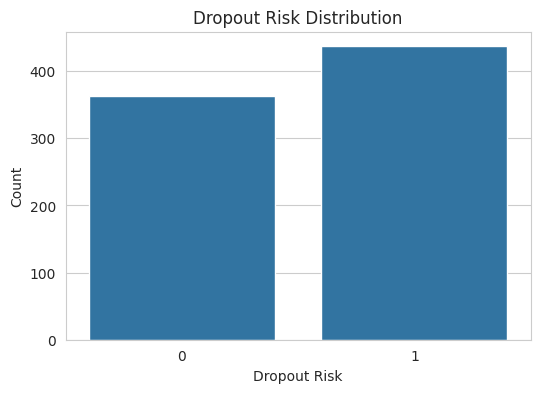

In [ ]:
# Visualize dropout risk distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(6,4))

sns.countplot(
    data=df_clean,
    x="Dropout_Risk"
)

plt.title("Dropout Risk Distribution")
plt.xlabel("Dropout Risk")
plt.ylabel("Count")

plt.show()

## Target Variable Analysis

The dataset contains:

- 437 students categorized as high dropout risk (54.6%)
- 363 students categorized as low dropout risk (45.4%)

The target variable is relatively balanced, reducing the risk of model bias toward one class and supporting reliable classification model development.

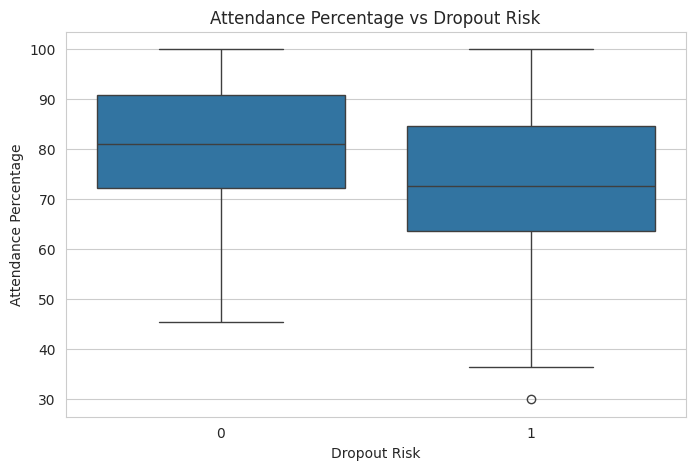

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_clean,
    x="Dropout_Risk",
    y="Attendance_Percent"
)

plt.title("Attendance Percentage vs Dropout Risk")
plt.xlabel("Dropout Risk")
plt.ylabel("Attendance Percentage")

plt.show()

### Attendance and Dropout Risk

Students classified as high dropout risk generally show lower attendance than students classified as low dropout risk.

The median attendance of the high-risk group is visibly lower, and the high-risk group contains a broader range of low-attendance observations. However, the distributions overlap, indicating that attendance alone does not completely distinguish students at risk.

This suggests that attendance may be an important predictor when combined with academic, mental health, financial, and lifestyle indicators.

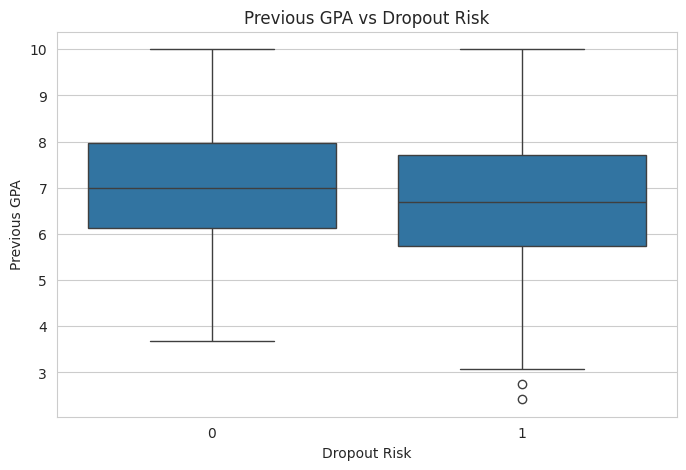

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_clean,
    x="Dropout_Risk",
    y="Previous_GPA"
)

plt.title("Previous GPA vs Dropout Risk")
plt.xlabel("Dropout Risk")
plt.ylabel("Previous GPA")

plt.show()

### Previous GPA and Dropout Risk

Previous GPA does not show a strong visible separation between the low-risk and high-risk groups.

The median GPA values of both groups are similar and the distributions overlap considerably. This suggests that GPA alone may not be sufficient to predict dropout risk and should be analyzed together with attendance, stress, burnout, financial stress, and other student well-being indicators.

Further analysis through feature importance and machine learning models will determine the true predictive value of GPA.

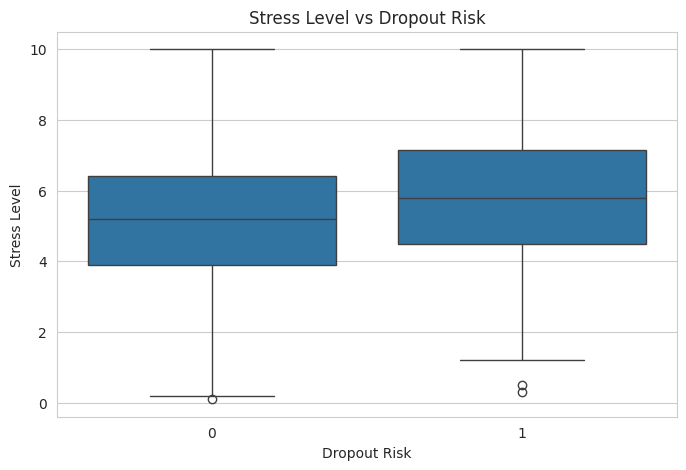

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_clean,
    x="Dropout_Risk",
    y="Stress_Level"
)

plt.title("Stress Level vs Dropout Risk")
plt.xlabel("Dropout Risk")
plt.ylabel("Stress Level")

plt.show()


### Stress Level and Dropout Risk

Based on the boxplot, students classified as high dropout risk tend to have slightly higher stress levels compared to those classified as low dropout risk.

While there is still some overlap between the two groups, the overall trend suggests that stress may be associated with an increased risk of dropping out. This indicates that mental health factors should be considered alongside academic and lifestyle variables when assessing student risk.

Further analysis using machine learning models will help determine how important stress is compared to other predictors.

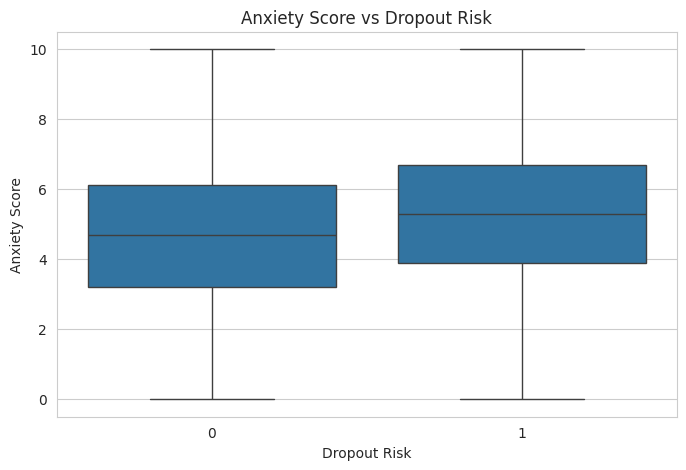

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_clean,
    x="Dropout_Risk",
    y="Anxiety_Score"
)

plt.title("Anxiety Score vs Dropout Risk")
plt.xlabel("Dropout Risk")
plt.ylabel("Anxiety Score")

plt.show()

### Anxiety Score and Dropout Risk

The chart shows that students classified as high dropout risk generally have slightly higher anxiety scores compared to students classified as low dropout risk.

Although the two groups still overlap, the overall trend suggests that anxiety may be associated with a higher likelihood of dropout risk. Similar to stress levels, anxiety appears to contribute to student risk but is unlikely to be the only factor involved.

These results support the inclusion of mental health indicators when building the final prediction model.

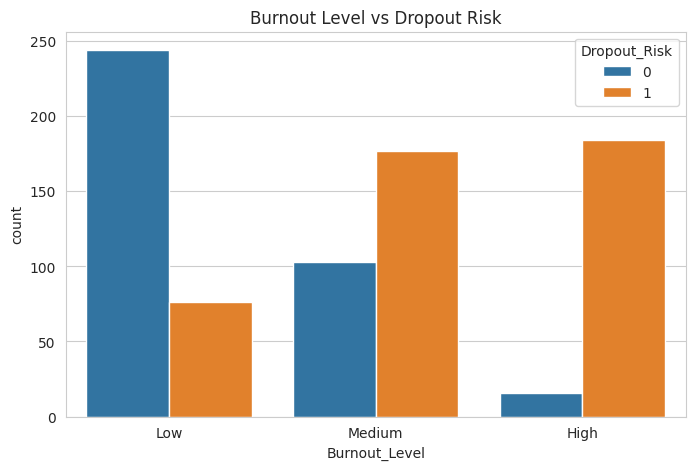

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_clean,
    x="Burnout_Level",
    hue="Dropout_Risk"
)

plt.title("Burnout Level vs Dropout Risk")

plt.show()

### Burnout Level and Dropout Risk

Among all variables examined so far, Burnout Level shows the strongest visible relationship with dropout risk.

Most students with low burnout are classified as low dropout risk, while students with medium and high burnout are more frequently classified as high dropout risk. The shift becomes especially noticeable in the high burnout category, where a large proportion of students are identified as being at risk.

This finding suggests that burnout may be one of the most important indicators of student dropout risk and should be investigated further during model training and feature importance analysis.

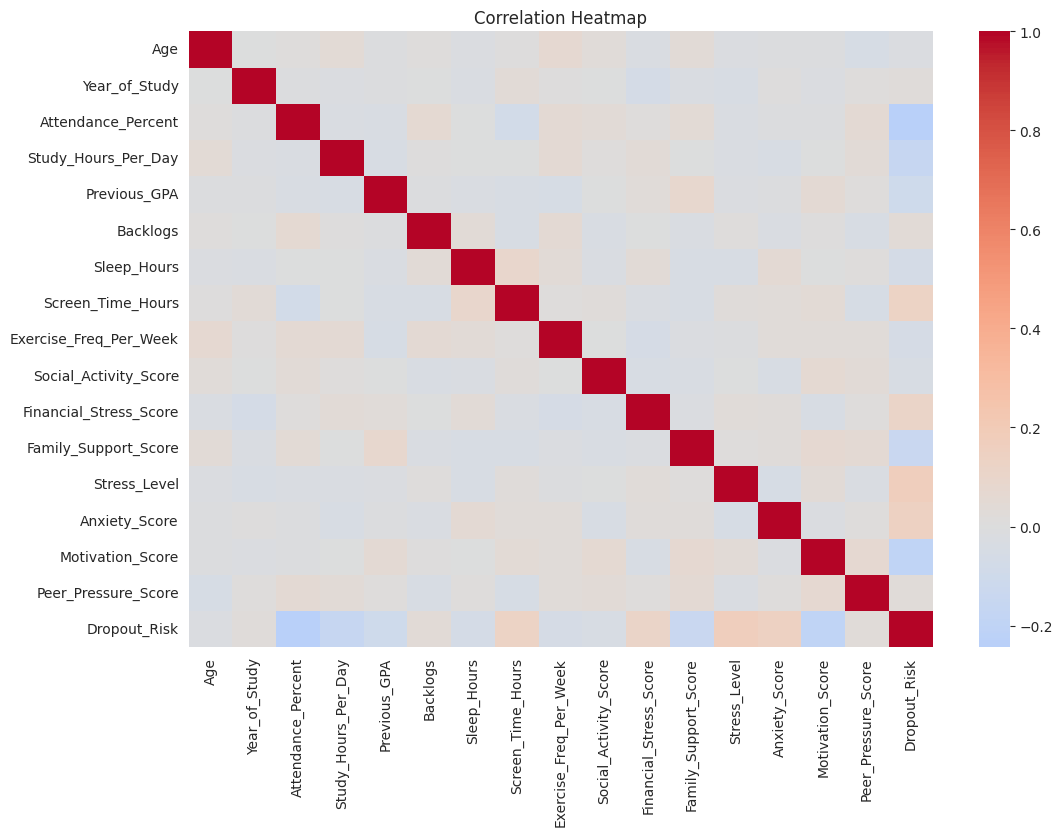

In [ ]:
plt.figure(figsize=(12,8))

corr_matrix = df_clean.select_dtypes(
    include=["int64", "float64"]
).corr()

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
dropout_corr = (
    corr_matrix["Dropout_Risk"]
    .drop("Dropout_Risk")
    .sort_values(ascending=False)
)

dropout_corr

,Dropout_Risk
Stress_Level,0.164330
Anxiety_Score,0.144505
Screen_Time_Hours,0.127055
Financial_Stress_Score,0.113520
Backlogs,0.037060
Peer_Pressure_Score,0.030696
Year_of_Study,0.018401
Age,-0.018536
Social_Activity_Score,-0.041064
Exercise_Freq_Per_Week,-0.055864


## Correlation Analysis

The correlation analysis shows that attendance percentage has the strongest negative relationship with dropout risk among the numerical variables. Students with higher attendance generally appear less likely to be classified as at risk.

Other factors that show a negative relationship with dropout risk include motivation score, study hours per day, family support score, and previous GPA.

On the other hand, stress level, anxiety score, screen time hours, and financial stress score show positive relationships with dropout risk. Students with higher values in these variables tend to have a greater likelihood of being classified as at risk.

Although the correlations are generally weak to moderate, the results support the idea that student dropout risk is influenced by a combination of academic performance, mental health, financial circumstances, and lifestyle factors rather than a single variable.

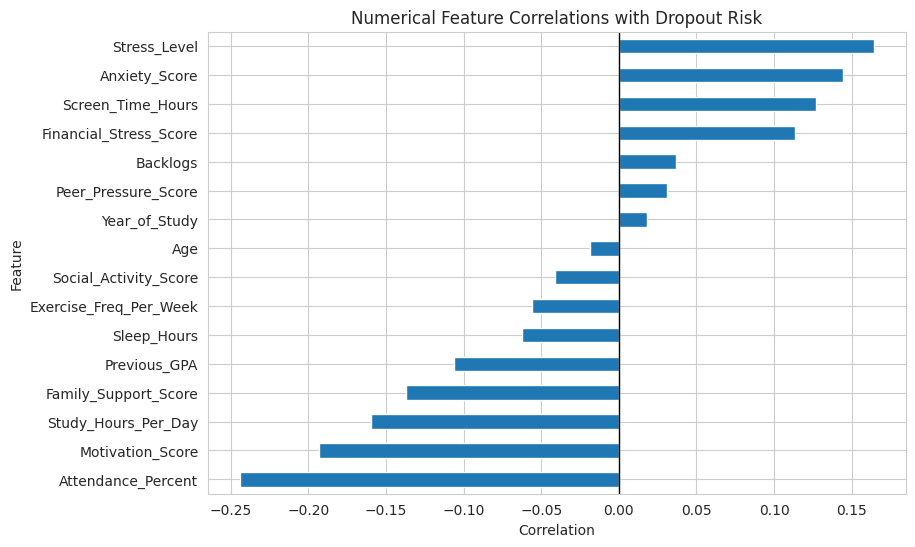

In [ ]:
plt.figure(figsize=(9, 6))

dropout_corr.sort_values().plot(
    kind="barh"
)

plt.title("Numerical Feature Correlations with Dropout Risk")
plt.xlabel("Correlation")
plt.ylabel("Feature")
plt.axvline(0, color="black", linewidth=1)

plt.show()

In [ ]:
df_clean.head()

,Age,Gender,Year_of_Study,Department,Residence_Type,Attendance_Percent,Study_Hours_Per_Day,Previous_GPA,Backlogs,Sleep_Hours,...,Family_Income_Bracket,Financial_Stress_Score,Family_Support_Score,Stress_Level,Anxiety_Score,Motivation_Score,Peer_Pressure_Score,Counseling_Access,Burnout_Level,Dropout_Risk
0,23,Female,2,Science,Hostel,93.0,4.1,7.13,2.0,6.2,...,Upper-Middle,5.5,10.0,4.0,NaN,7.0,NaN,No,Low,0
1,20,Female,4,Engineering,Day Scholar,94.3,0.0,10.00,0.0,NaN,...,Low,3.7,4.0,5.5,5.1,9.3,2.8,Yes,Medium,1
2,24,Male,2,Business,PG/Rented,61.2,2.6,8.02,0.0,4.2,...,Middle,4.8,8.1,9.0,5.2,5.7,5.4,No,High,1
3,21,Female,4,Medicine,Hostel,66.9,3.1,5.34,1.0,5.7,...,Lower-Middle,7.0,6.6,2.8,4.2,5.1,3.9,No,High,1
4,23,Female,1,Engineering,NaN,84.8,2.9,4.45,1.0,8.0,...,Lower-Middle,1.3,7.3,0.9,6.4,8.1,5.1,No,Low,0


In [ ]:
# Feature Engineering: Combine Stress, Anxiety, and Financial Stress scores into a single normalized index
df_clean["Mental_Health_Index"] = (
    df_clean["Stress_Level"] +
    df_clean["Anxiety_Score"] +
    df_clean["Financial_Stress_Score"]
) / 3

In [ ]:
df_clean[
    [
        "Stress_Level",
        "Anxiety_Score",
        "Financial_Stress_Score",
        "Mental_Health_Index"
    ]
].head()

,Stress_Level,Anxiety_Score,Financial_Stress_Score,Mental_Health_Index
0,4.0,NaN,5.5,NaN
1,5.5,5.1,3.7,4.766667
2,9.0,5.2,4.8,6.333333
3,2.8,4.2,7.0,4.666667
4,0.9,6.4,1.3,2.866667


In [ ]:
pd.crosstab(
    df_clean["Burnout_Level"],
    df_clean["Dropout_Risk"],
    normalize="index"
) * 100

Dropout_Risk,0,1
Burnout_Level,,
High,8.000000,92.000000
Low,76.250000,23.750000
Medium,36.785714,63.214286


### Burnout Level and Dropout Risk

The percentage table shows a clear increase in dropout risk as burnout becomes more severe.

Among students with low burnout, only 23.8% are classified as high dropout risk. This increases to 63.2% for students with medium burnout and reaches 92.0% for students with high burnout.

This is the strongest relationship found in the analysis so far. It suggests that burnout could be an important indicator when identifying students who may need additional support. However, this result only shows an association within this dataset and does not prove that burnout directly causes students to drop out.

In [ ]:
income_dropout_table = pd.crosstab(
    df_clean["Family_Income_Bracket"],
    df_clean["Dropout_Risk"],
    normalize="index"
) * 100

income_dropout_table.round(2)

Dropout_Risk,0,1
Family_Income_Bracket,,
High,60.87,39.13
Low,31.58,68.42
Lower-Middle,39.65,60.35
Middle,45.87,54.13
Upper-Middle,53.44,46.56


### Burnout Level and Dropout Risk

The relationship between burnout level and dropout risk is very clear.

Students with low burnout are mostly classified as low dropout risk, while students with high burnout are overwhelmingly classified as high dropout risk. The percentage of students classified as at risk increases consistently from the low burnout group to the high burnout group.

Among students with high burnout, 92% are classified as high dropout risk, compared to only 23.8% of students in the low burnout group.

Based on the current analysis, burnout appears to be one of the strongest indicators of dropout risk in this dataset.

In [ ]:
pd.crosstab(
    df_clean["Counseling_Access"],
    df_clean["Dropout_Risk"],
    normalize="index"
) * 100

Dropout_Risk,0,1
Counseling_Access,,
No,42.429907,57.570093
Yes,51.320755,48.679245


### Counseling Access and Dropout Risk

Students with access to counseling appear to have a lower percentage of high dropout risk compared to students without counseling access.

Among students without counseling access, 57.6% are classified as high dropout risk. This decreases to 48.7% among students who have access to counseling services.

Although the difference is not as large as the burnout findings, the results suggest that support services may play a role in reducing student risk and could be an important factor when designing intervention programs.

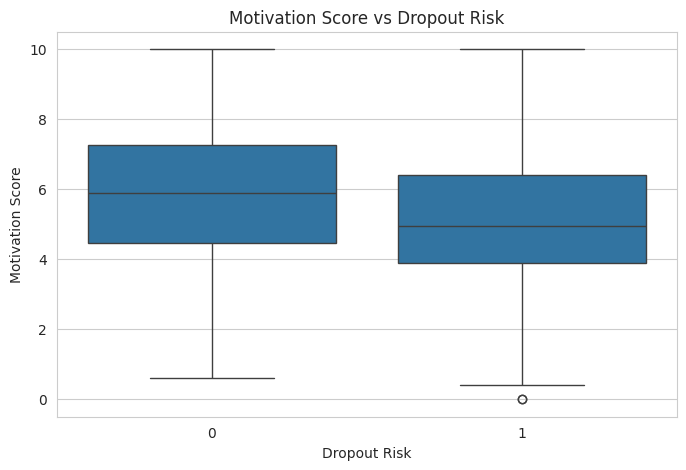

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_clean,
    x="Dropout_Risk",
    y="Motivation_Score"
)

plt.title("Motivation Score vs Dropout Risk")
plt.xlabel("Dropout Risk")
plt.ylabel("Motivation Score")

plt.show()

### Motivation Score and Dropout Risk

Students classified as low dropout risk generally show higher motivation scores compared to students classified as high dropout risk.

Although the separation is not as strong as the relationship observed for burnout, the overall trend indicates that motivation may play an important role in student retention. Students with higher motivation levels appear less likely to fall into the high-risk category.

This finding supports the idea that student engagement and personal motivation should be considered alongside academic and mental health factors when assessing dropout risk.

In [ ]:
pd.crosstab(
    df_clean["Part_Time_Job"],
    df_clean["Dropout_Risk"],
    normalize="index"
) * 100

Dropout_Risk,0,1
Part_Time_Job,,
No,48.994516,51.005484
Yes,37.719298,62.280702


### Part-Time Job and Dropout Risk

Students with a part-time job appear to have a higher percentage of dropout risk compared to students without a part-time job.

Among students who work part-time, 62.3% are classified as high dropout risk, compared to 51.6% among students who do not work part-time.

One possible explanation is that balancing academic responsibilities and work commitments may increase stress, reduce available study time, and contribute to student burnout. However, further analysis is needed before drawing strong conclusions.

In [ ]:
for col in categorical_cols:
    print(f"\n{col}")
    print(df_clean[col].unique())


Gender
['Female' 'Male' 'Other' nan]

Department
['Science' 'Engineering' 'Business' 'Medicine' 'Law' nan 'Arts']

Residence_Type
['Hostel' 'Day Scholar' 'PG/Rented' nan]

Part_Time_Job
['Yes' 'No' nan]

Family_Income_Bracket
['Upper-Middle' 'Low' 'Middle' 'Lower-Middle' 'High' nan]

Counseling_Access
['No' 'Yes']

Burnout_Level
['Low' 'Medium' 'High']


In [ ]:
df_clean[
    [
        "Attendance_Percent",
        "Study_Hours_Per_Day",
        "Previous_GPA",
        "Backlogs"
    ]
].describe()

,Attendance_Percent,Study_Hours_Per_Day,Previous_GPA,Backlogs
count,749.000000,765.000000,765.000000,785.000000
mean,76.884246,3.158431,6.859242,0.824204
std,14.258149,1.558711,1.401110,0.939320
min,30.000000,0.000000,2.420000,0.000000
25%,66.200000,2.100000,5.880000,0.000000
50%,77.400000,3.100000,6.860000,1.000000
75%,88.600000,4.200000,7.800000,1.000000
max,100.000000,8.100000,10.000000,6.000000


In [ ]:
# Feature Engineering: Construct an Academic Engagement Index scaling the factors between 0 and 1
df_clean["Academic_Engagement_Index"] = (
    (
        df_clean["Attendance_Percent"] / 100
    )  # Normalize attendance to [0, 1]
    +
    (
        df_clean["Study_Hours_Per_Day"] / 8.1
    )  # Normalize study hours relative to the maximum observed (8.1)
    +
    (
        df_clean["Previous_GPA"] / 10
    )  # Normalize GPA to [0, 1]
) / 3

### Academic Engagement Index

An Academic Engagement Index was created to summarize key academic behaviors associated with student success.

The index combines:

- Attendance Percentage
- Study Hours Per Day
- Previous GPA

All variables were normalized before aggregation to prevent any single variable from dominating the index because of scale differences.

Higher values indicate stronger academic engagement and academic performance.

In [ ]:
df_clean["Mental_Health_Index"] = (
    df_clean["Stress_Level"] +
    df_clean["Anxiety_Score"] +
    df_clean["Financial_Stress_Score"]
) / 3

In [ ]:
df_clean[
    [
        "Stress_Level",
        "Anxiety_Score",
        "Financial_Stress_Score",
        "Mental_Health_Index"
    ]
].head()

,Stress_Level,Anxiety_Score,Financial_Stress_Score,Mental_Health_Index
0,4.0,NaN,5.5,NaN
1,5.5,5.1,3.7,4.766667
2,9.0,5.2,4.8,6.333333
3,2.8,4.2,7.0,4.666667
4,0.9,6.4,1.3,2.866667


### Mental Health Index

A Mental Health Index was created to represent overall psychological burden experienced by students.

The index combines:

- Stress Level
- Anxiety Score
- Financial Stress Score

Higher values indicate greater psychological and financial stress, which may increase the likelihood of student dropout risk.

# Feature Selection

Feature selection helps identify which variables contribute the most to predicting student dropout risk.

This step improves model interpretability and helps reduce unnecessary features before training machine learning models.

In [ ]:
feature_corr = (
    df_clean
    .select_dtypes(include=["int64", "float64"])
    .corr()["Dropout_Risk"]
    .drop("Dropout_Risk")
)

feature_corr.sort_values(
    key=abs,
    ascending=False
)

,Dropout_Risk
Academic_Engagement_Index,-0.291122
Attendance_Percent,-0.244185
Mental_Health_Index,0.226769
Motivation_Score,-0.193057
Stress_Level,0.164330
Study_Hours_Per_Day,-0.159725
Anxiety_Score,0.144505
Family_Support_Score,-0.137292
Screen_Time_Hours,0.127055
Financial_Stress_Score,0.113520


## Feature Selection Results

The correlation-based feature selection results show that the engineered features created during feature engineering are among the strongest predictors of dropout risk.

The Academic Engagement Index shows the strongest relationship with dropout risk, with a correlation of -0.291. This suggests that students with stronger academic engagement are generally less likely to be classified as at risk.

The Mental Health Index shows a positive correlation of 0.235, indicating that higher levels of stress, anxiety, and financial stress are associated with greater dropout risk.

Among the original variables, Attendance Percentage, Motivation Score, Stress Level, Study Hours Per Day, and Anxiety Score also show meaningful relationships with dropout risk.

These findings suggest that student dropout risk is influenced by a combination of academic engagement, mental health, and personal motivation rather than a single factor.

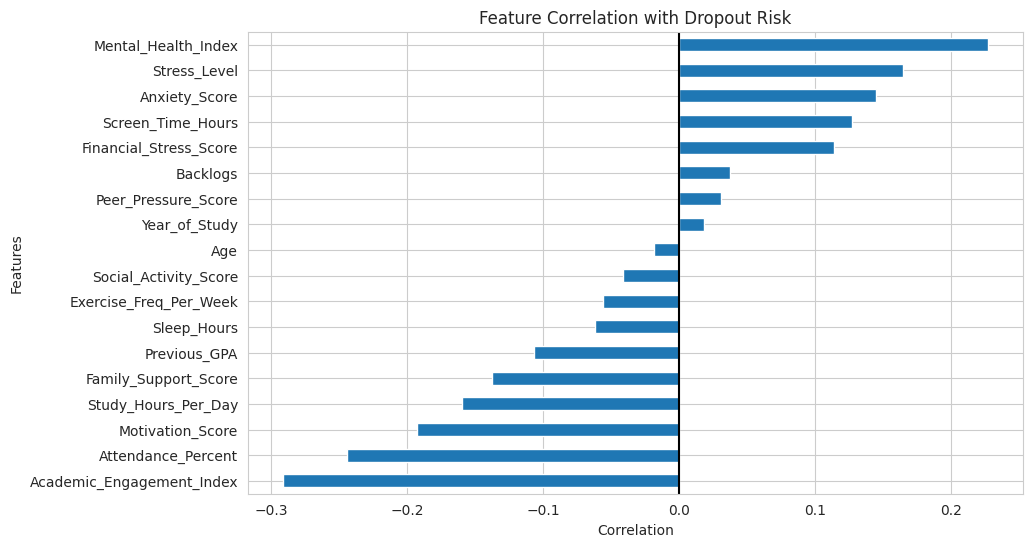

In [ ]:
plt.figure(figsize=(10,6))

feature_corr.sort_values().plot(
    kind="barh"
)

plt.axvline(
    0,
    color="black"
)

plt.title(
    "Feature Correlation with Dropout Risk"
)

plt.xlabel("Correlation")
plt.ylabel("Features")

plt.show()

### Correlation-Based Feature Ranking

The correlation analysis confirms that the engineered features created during feature engineering are among the strongest predictors of dropout risk.

The Academic Engagement Index shows the strongest negative relationship with dropout risk, suggesting that students who are more academically engaged are generally less likely to be classified as at risk.

The Mental Health Index shows one of the strongest positive relationships with dropout risk, indicating that increased stress, anxiety, and financial stress are associated with higher dropout risk.

Among the original variables, attendance percentage, motivation score, study hours per day, family support score, stress level, and anxiety score also demonstrate meaningful relationships with dropout risk.

These findings suggest that dropout risk is influenced by a combination of academic engagement, mental health, and support-related factors rather than a single variable.

# Feature Selection (Embedded Method)

In addition to correlation analysis, an embedded feature selection method is applied using Random Forest feature importance.

Unlike correlation analysis, Random Forest can identify nonlinear relationships and interactions between variables.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

In [ ]:
df_model = df_clean.copy()

In [ ]:
label_encoders = {}

# Encode categorical string columns to numeric labels for machine learning compatibility
for col in categorical_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(
        df_model[col]
    )
    # Store the encoders for future use or decoding
    label_encoders[col] = le

In [ ]:
X = df_model.drop(
    columns=["Dropout_Risk"]
)

y = df_model["Dropout_Risk"]

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X, y)

RandomForestClassifier(n_estimators=200, random_state=42)

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
22,Burnout_Level,0.133591
5,Attendance_Percent,0.072513
24,Academic_Engagement_Index,0.072099
19,Motivation_Score,0.061093
23,Mental_Health_Index,0.058581
6,Study_Hours_Per_Day,0.050374
16,Family_Support_Score,0.049941
17,Stress_Level,0.048894
10,Screen_Time_Hours,0.048000
12,Social_Activity_Score,0.047991


### Random Forest Feature Importance Results

The Random Forest results support the patterns found during the earlier EDA and correlation analysis.

Burnout Level is the most important feature by a noticeable margin. This matches the earlier finding that students with higher burnout levels were much more likely to be classified as high dropout risk.

The Academic Engagement Index, Attendance Percentage, Mental Health Index, and Motivation Score also ranked among the top features. This suggests that both academic engagement and student well-being provide useful information when predicting dropout risk.

The two engineered features also performed well, which shows that combining related variables helped capture broader academic and mental health patterns.

However, feature importance only shows how useful each variable was to the Random Forest. It does not show whether a feature increases or decreases dropout risk.

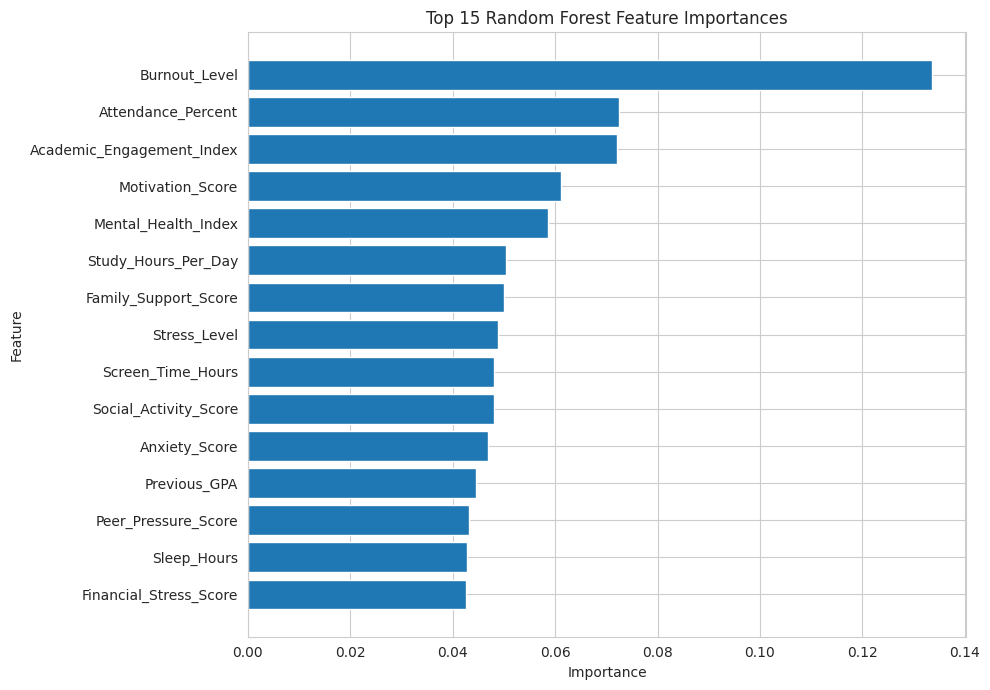

In [ ]:
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Embedded Feature Selection Summary

The Random Forest ranking confirms that Burnout Level is the strongest feature in the current dataset.

Academic Engagement Index, Attendance Percentage, Mental Health Index, and Motivation Score also provide useful predictive information. These features will be retained for later model development and explainability analysis.

The results also show that dropout risk is influenced by a combination of academic, mental health, lifestyle, and support-related factors.

# Dimensionality Reduction (PCA)

Principal Component Analysis (PCA) is used to determine whether the dataset can be represented using fewer dimensions while retaining most of the information.

Since the variables use different scales, the data must first be standardized before PCA is applied.

The goal is to understand how much variance can be explained by a smaller number of components and to identify possible redundancy among features.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
pca_input = df_model.select_dtypes(
    include=["int64", "float64"]
).drop(
    columns=["Dropout_Risk"]
)

In [ ]:
print("Rows:", pca_input.shape[0])
print("Features:", pca_input.shape[1])

pca_input.head()

Rows: 800
Features: 25


,Age,Gender,Year_of_Study,Department,Residence_Type,Attendance_Percent,Study_Hours_Per_Day,Previous_GPA,Backlogs,Sleep_Hours,...,Financial_Stress_Score,Family_Support_Score,Stress_Level,Anxiety_Score,Motivation_Score,Peer_Pressure_Score,Counseling_Access,Burnout_Level,Mental_Health_Index,Academic_Engagement_Index
0,23,0,2,5,1,93.0,4.1,7.13,2.0,6.2,...,5.5,10.0,4.0,NaN,7.0,NaN,0,1,NaN,0.716391
1,20,0,4,2,0,94.3,0.0,10.00,0.0,NaN,...,3.7,4.0,5.5,5.1,9.3,2.8,1,2,4.766667,0.647667
2,24,1,2,1,2,61.2,2.6,8.02,0.0,4.2,...,4.8,8.1,9.0,5.2,5.7,5.4,0,0,6.333333,0.578329
3,21,0,4,4,1,66.9,3.1,5.34,1.0,5.7,...,7.0,6.6,2.8,4.2,5.1,3.9,0,0,4.666667,0.528572
4,23,0,1,2,3,84.8,2.9,4.45,1.0,8.0,...,1.3,7.3,0.9,6.4,8.1,5.1,0,1,2.866667,0.550342


In [ ]:
scaler = StandardScaler()

scaled_features = scaler.fit_transform(
    pca_input
)

In [ ]:
from sklearn.impute import SimpleImputer

# 1. Impute missing values with the median
imputer = SimpleImputer(strategy="median")
pca_input_imputed = imputer.fit_transform(pca_input)

# 2. Scale the imputed features
scaler = StandardScaler()
scaled_features_clean = scaler.fit_transform(pca_input_imputed)

# 3. Fit PCA
pca = PCA()
pca.fit(scaled_features_clean)

# 4. Create explained variance DataFrame
explained_variance = pd.DataFrame({
    "Principal Component": range(1, len(pca.explained_variance_ratio_) + 1),
    "Explained Variance": pca.explained_variance_ratio_
})

explained_variance.head(10)

,Principal Component,Explained Variance
0,1,0.085218
1,2,0.076845
2,3,0.049981
3,4,0.048705
4,5,0.047314
5,6,0.046262
6,7,0.045582
7,8,0.044218
8,9,0.043917
9,10,0.043172


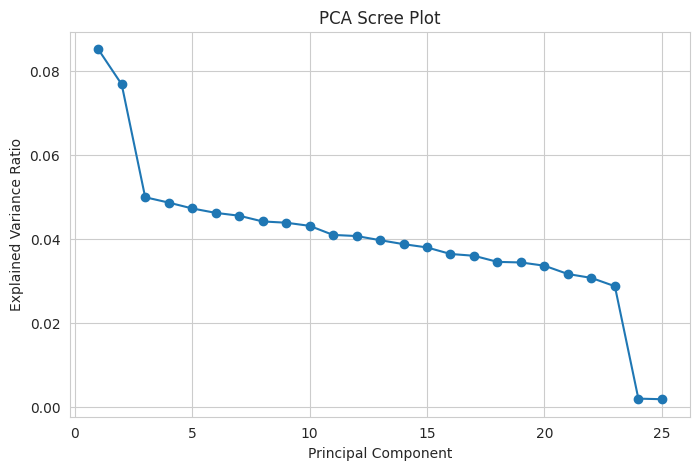

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    range(
        1,
        len(pca.explained_variance_ratio_) + 1
    ),
    pca.explained_variance_ratio_,
    marker="o"
)

plt.title("PCA Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")

plt.show()

## PCA Interpretation

The scree plot shows that the first few principal components explain a larger proportion of the variance than the remaining components.

A noticeable decline is observed after the first two to three components, indicating that these components capture a relatively higher amount of information from the dataset. However, the decrease becomes more gradual afterward, suggesting that important information is distributed across multiple features rather than concentrated in only a few dimensions.

This indicates that while PCA can reduce dimensionality, retaining the original features may still be beneficial for model interpretability and explainability.

For this project, PCA will primarily be used for exploratory analysis and visualization rather than replacing the original feature set for model training.

In [ ]:
explained_variance["Cumulative Variance"] = (
    explained_variance["Explained Variance"].cumsum()
)

explained_variance.head(10)

,Principal Component,Explained Variance,Cumulative Variance
0,1,0.085218,0.085218
1,2,0.076845,0.162062
2,3,0.049981,0.212044
3,4,0.048705,0.260749
4,5,0.047314,0.308063
5,6,0.046262,0.354324
6,7,0.045582,0.399906
7,8,0.044218,0.444124
8,9,0.043917,0.488041
9,10,0.043172,0.531213


##PCA Results

The first principal component explains approximately 8.52% of the total variance, while the first two principal components together explain approximately 16.21%.

The cumulative variance table shows that the information in the dataset is distributed across many variables rather than being concentrated in only a few components.

This suggests that most features contribute meaningful information and that aggressive dimensionality reduction may not be beneficial for this project.

For this reason, PCA will be used primarily as an exploratory analysis technique, while the original features will be retained for model development and interpretation.

In [ ]:
import numpy as np

components_80 = np.argmax(
    pca.explained_variance_ratio_.cumsum() >= 0.80
) + 1

components_90 = np.argmax(
    pca.explained_variance_ratio_.cumsum() >= 0.90
) + 1

components_95 = np.argmax(
    pca.explained_variance_ratio_.cumsum() >= 0.95
) + 1

print("Components needed for 80% variance:", components_80)
print("Components needed for 90% variance:", components_90)
print("Components needed for 95% variance:", components_95)

Components needed for 80% variance: 17
Components needed for 90% variance: 20
Components needed for 95% variance: 22


### PCA Results Summary

The PCA results show that the dataset's information is distributed across many variables rather than concentrated in only a few dimensions.

A total of 17 principal components are required to explain 80% of the variance, while 20 and 22 components are required to explain 90% and 95% of the variance, respectively.

This suggests that many variables contain useful information and that aggressive dimensionality reduction may not be beneficial for this project.

For this reason, the original features will be retained for model development, while PCA will be used primarily as an exploratory tool.


In [ ]:
df_clean.to_csv(
    "student_dropout_model_ready.csv",
    index=False
)

print("Model-ready dataset saved successfully.")

Model-ready dataset saved successfully.


# Step 4: Model Implementation

This section develops and evaluates multiple machine learning models for predicting student dropout risk.

The objective is to compare model performance and identify the most effective model for predicting student dropout risk.

In [ ]:
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
df_model = pd.read_csv(
    "student_dropout_model_ready.csv"
)

In [ ]:
df_model.shape

(800, 26)

In [ ]:
df_model.columns.tolist()

['Age',
 'Gender',
 'Year_of_Study',
 'Department',
 'Residence_Type',
 'Attendance_Percent',
 'Study_Hours_Per_Day',
 'Previous_GPA',
 'Backlogs',
 'Sleep_Hours',
 'Screen_Time_Hours',
 'Exercise_Freq_Per_Week',
 'Social_Activity_Score',
 'Part_Time_Job',
 'Family_Income_Bracket',
 'Financial_Stress_Score',
 'Family_Support_Score',
 'Stress_Level',
 'Anxiety_Score',
 'Motivation_Score',
 'Peer_Pressure_Score',
 'Counseling_Access',
 'Burnout_Level',
 'Dropout_Risk',
 'Mental_Health_Index',
 'Academic_Engagement_Index']

In [ ]:
df_model.select_dtypes(
    include=["object"]
).columns.tolist()

['Gender',
 'Department',
 'Residence_Type',
 'Part_Time_Job',
 'Family_Income_Bracket',
 'Counseling_Access',
 'Burnout_Level']

In [ ]:
categorical_cols = [
    'Gender',
    'Department',
    'Residence_Type',
    'Part_Time_Job',
    'Family_Income_Bracket',
    'Counseling_Access',
    'Burnout_Level'
]

categorical_cols

['Gender',
 'Department',
 'Residence_Type',
 'Part_Time_Job',
 'Family_Income_Bracket',
 'Counseling_Access',
 'Burnout_Level']

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
df_encoded = df_model.copy()

In [ ]:
label_encoders = {}

for col in categorical_cols:

    le = LabelEncoder()

    df_encoded[col] = le.fit_transform(
        df_encoded[col]
    )

    label_encoders[col] = le

In [ ]:
df_encoded.head()

,Age,Gender,Year_of_Study,Department,Residence_Type,Attendance_Percent,Study_Hours_Per_Day,Previous_GPA,Backlogs,Sleep_Hours,...,Family_Support_Score,Stress_Level,Anxiety_Score,Motivation_Score,Peer_Pressure_Score,Counseling_Access,Burnout_Level,Dropout_Risk,Mental_Health_Index,Academic_Engagement_Index
0,23,0,2,5,1,93.0,4.1,7.13,2.0,6.2,...,10.0,4.0,NaN,7.0,NaN,0,1,0,NaN,0.716391
1,20,0,4,2,0,94.3,0.0,10.00,0.0,NaN,...,4.0,5.5,5.1,9.3,2.8,1,2,1,4.766667,0.647667
2,24,1,2,1,2,61.2,2.6,8.02,0.0,4.2,...,8.1,9.0,5.2,5.7,5.4,0,0,1,6.333333,0.578329
3,21,0,4,4,1,66.9,3.1,5.34,1.0,5.7,...,6.6,2.8,4.2,5.1,3.9,0,0,1,4.666667,0.528572
4,23,0,1,2,3,84.8,2.9,4.45,1.0,8.0,...,7.3,0.9,6.4,8.1,5.1,0,1,0,2.866667,0.550342


## Train-Test Split

The dataset is divided into training and testing sets before model training.

The training set is used to train the model, while the testing set is used to evaluate how well the model performs on unseen data.

A stratified split is used to preserve the original class distribution of the target variable.

In [ ]:
X = df_encoded.drop(
    columns=["Dropout_Risk"]
)

y = df_encoded["Dropout_Risk"]

In [ ]:
# Perform a stratified train-test split to ensure class ratios are identical in training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (640, 25)
X_test : (160, 25)
y_train: (640,)
y_test : (160,)


## Logistic Regression Baseline Model

Logistic Regression is used as the baseline classification model.

This model is simple, interpretable, and provides a useful benchmark against which more advanced models such as Random Forest and XGBoost can be compared.

The objective is to evaluate its ability to predict student dropout risk using the available academic, mental health, lifestyle, support, and engineered features.

In [ ]:
# Use SimpleImputer to handle missing values before training Logistic Regression
from sklearn.impute import SimpleImputer

# Initialize the imputer to fill NaNs with the median
imputer = SimpleImputer(strategy="median")

# Impute missing values in train and test sets
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Update local variables so subsequent cells can run without error
X_train = X_train_imputed
X_test = X_test_imputed

# Initialize and fit the Baseline Logistic Regression classifier
log_model = LogisticRegression(
    max_iter=5000
)

log_model.fit(
    X_train,
    y_train
)

LogisticRegression(max_iter=5000)

In [ ]:
y_pred = log_model.predict(
    X_test
)

In [ ]:
print(
    "Accuracy:",
    accuracy_score(
        y_test,
        y_pred
    )
)

print(
    "Precision:",
    precision_score(
        y_test,
        y_pred
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        y_pred
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        y_pred
    )
)

Accuracy: 0.7
Precision: 0.7241379310344828
Recall: 0.7241379310344828
F1 Score: 0.7241379310344828


### Logistic Regression Results

The Logistic Regression model serves as the project's baseline benchmark, evaluated on the test set of 160 students ($N = 160$).

**Model Performance:**
- **Accuracy:** 70.00%
- **Precision:** 72.41%
- **Recall:** 72.41%
- **F1 Score:** 72.41%

With an overall accuracy of 70.00%, the model substantially outperforms random guessing and improves upon the naive majority-class baseline (54.6%), indicating genuine predictive capability from the combined academic, psychological, and lifestyle indicators.
Precision, Recall, and F1 Score are identical at 72.41%. This mathematical alignment occurs because the model generated an equal number of Type I errors (24 False Positives) and Type II errors (24 False Negatives). Out of 87 actual high-risk students, the model successfully identified 63 (True Positives), while incorrectly flagging 24 low-risk students. A 72.41% Recall means the classifier captures nearly three-quarters of at-risk students for early intervention, maintaining an equal balance between identifying vulnerable individuals and avoiding excessive false alarms for academic counselors.

Overall, Logistic Regression establishes a competitive, well-calibrated baseline that will serve as the benchmark for nonlinear and ensemble models (Decision Tree, Random Forest, and XGBoost).


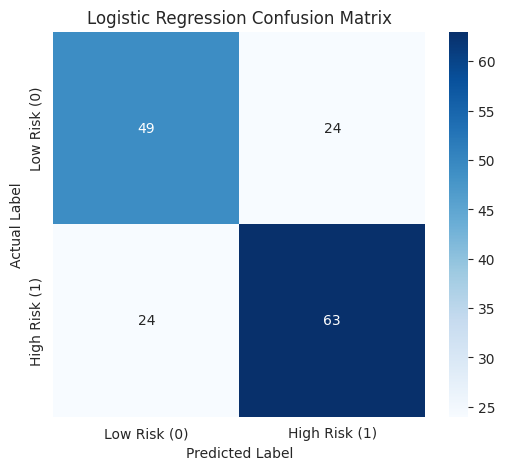

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk (0)", "High Risk (1)"],
    yticklabels=["Low Risk (0)", "High Risk (1)"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.show()

## Logistic Regression Confusion Matrix

The confusion matrix shows that the Logistic Regression model correctly classified 49 low-risk students (True Negatives) and 63 high-risk students (True Positives).

However, the model produced symmetric errors across both classes:
- 24 low-risk students incorrectly classified as high risk (False Positives / Type I error)
- 24 high-risk students incorrectly classified as low risk (False Negatives / Type II error)

The model successfully identifies nearly three-quarters of vulnerable students, reflected in the recall score of 72.41% (63 out of 87 actual high-risk students). Because the false positives and false negatives are identical (FP = FN = 24), the model maintains an equal trade-off between precision and recall.

Overall, Logistic Regression establishes a balanced, viable baseline and provides a clear benchmark for evaluating more complex nonlinear and ensemble models.


## Decision Tree Model

A Decision Tree model is evaluated to determine whether a nonlinear model can improve prediction performance compared to Logistic Regression.

Decision Trees are capable of identifying nonlinear relationships and interactions between variables, making them a useful comparison model.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
tree_model = DecisionTreeClassifier(
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)

DecisionTreeClassifier(random_state=42)

In [ ]:
tree_pred = tree_model.predict(
    X_test
)

In [ ]:
print(
    "Accuracy:",
    accuracy_score(
        y_test,
        tree_pred
    )
)

print(
    "Precision:",
    precision_score(
        y_test,
        tree_pred
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        tree_pred
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        tree_pred
    )
)

Accuracy: 0.59375
Precision: 0.6195652173913043
Recall: 0.6551724137931034
F1 Score: 0.6368715083798883


## Decision Tree Results

The Decision Tree model achieved lower performance compared to Logistic Regression.

Although Decision Trees can capture nonlinear relationships, the model produced lower Accuracy, Recall, and F1 Score on the test dataset. This suggests that the model may be overfitting to the training data and is less effective at generalizing to unseen observations.

Based on the current results, Logistic Regression remains the stronger baseline model.

## Random Forest Model

Random Forest is an ensemble learning method that combines multiple decision trees to improve prediction performance and reduce overfitting.

It is expected to outperform the standalone Decision Tree because predictions are based on the combined results of many trees rather than a single tree.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Initialize the ensemble Random Forest Classifier with 300 estimators for robust predictions
f_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

In [ ]:
f_model.fit(
    X_train,
    y_train
)

RandomForestClassifier(n_estimators=300, random_state=42)

In [ ]:
rf_pred = f_model.predict(
    X_test
)

In [ ]:
print(
    "Accuracy:",
    accuracy_score(
        y_test,
        rf_pred
    )
)

print(
    "Precision:",
    precision_score(
        y_test,
        rf_pred
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        rf_pred
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        rf_pred
    )
)

Accuracy: 0.68125
Precision: 0.7045454545454546
Recall: 0.7126436781609196
F1 Score: 0.7085714285714285


## Random Forest Results

The Random Forest model achieved the following performance metrics on the test dataset:

- Accuracy: 68.13%
- Precision: 70.45%
- Recall: 71.26%
- F1 Score: 70.86%

Compared to the baseline Logistic Regression model (70.00% Accuracy, 72.41% Recall, and 72.41% F1 Score), the default Random Forest model yielded slightly lower overall scores across all primary metrics. While ensemble tree methods are designed to model nonlinear interactions and complex feature relationships, the un-tuned Random Forest showed signs of variance and slightly reduced generalization on unseen test data compared to the linear baseline.

Despite this slight drop against Logistic Regression, Random Forest significantly outperformed the standalone Decision Tree and maintains solid predictive utility, capturing over 71% of high-risk students. Hyperparameter tuning (such as adjusting tree depth, minimum leaf samples, and feature sub-sampling) or exploring gradient boosted trees (such as XGBoost) may help improve its performance further.


In [ ]:
rf_cm = confusion_matrix(
    y_test,
    rf_pred
)

rf_cm

array([[47, 26],
       [25, 62]])

##Random Forest Confusion Matrix

The confusion matrix shows that the Random Forest model correctly classified 47 low-risk students (True Negatives) and 62 high-risk students (True Positives).

The model incorrectly classified:

⚬ 26 low-risk students as high-risk students (False Positives / Type I error)
⚬ 25 high-risk students as low-risk students (False Negatives / Type II error)

Compared to the Logistic Regression baseline (which achieved 49 True Negatives and 63 True Positives), Random Forest had slightly more classification errors on this split. It correctly flagged 62 out of 87 actual at-risk students, resulting in a Recall of 71.26%.

While it remains competitive and clearly outperforms the standalone Decision Tree, fine-tuning hyperparameters or evaluating gradient-boosted models like XGBoost may help reduce the false negative rate further.

##XGBoost Model

An XGBoost model is evaluated to determine whether a gradient boosting approach can improve prediction performance compared to Logistic Regression, Decision Tree, and Random Forest models.
Unlike Random Forest which builds trees independently in parallel, XGBoost builds decision trees sequentially to correct the errors of previous trees, making it effective at capturing complex interactions and hard-to-classify cases.

In [ ]:
from xgboost import XGBClassifier

# Initialize and train the XGBoost Classifier
xgb_model = XGBClassifier(n_estimators=300, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

# Make predictions on the test set
xgb_pred = xgb_model.predict(X_test)

# Calculate and print metrics
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred))
print("Recall:", recall_score(y_test, xgb_pred))
print("F1 Score:", f1_score(y_test, xgb_pred))

Accuracy: 0.68125
Precision: 0.7
Recall: 0.7241379310344828
F1 Score: 0.711864406779661


##XGBoost Results

The XGBoost model achieved the following performance metrics on the test dataset:

⚬ Accuracy: 68.13%
⚬ Precision: 70.00%
⚬ Recall: 72.41%
⚬ F1 Score: 71.19%

Compared to Random Forest (68.13% Accuracy, 71.26% Recall, 70.86% F1 Score), XGBoost matched overall accuracy and achieved a slightly higher F1 Score by matching the baseline Logistic Regression's Recall of 72.41%.

By sequentially training trees to focus on previous errors, XGBoost proved effective at capturing positive at-risk instances. It outperforms the standalone Decision Tree and provides a competitive ensemble alternative, though Logistic Regression still maintains the highest overall precision and accuracy on this split.

# Model Comparison

Four classification models were evaluated:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. XGBoost

The objective was to identify the model that provides the strongest predictive performance while maintaining reasonable interpretability.

In [ ]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, tree_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, xgb_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, tree_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, xgb_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, tree_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, xgb_pred)
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.70000,0.724138,0.724138,0.724138
1,Decision Tree,0.59375,0.619565,0.655172,0.636872
2,Random Forest,0.68125,0.704545,0.712644,0.708571
3,XGBoost,0.68125,0.700000,0.724138,0.711864


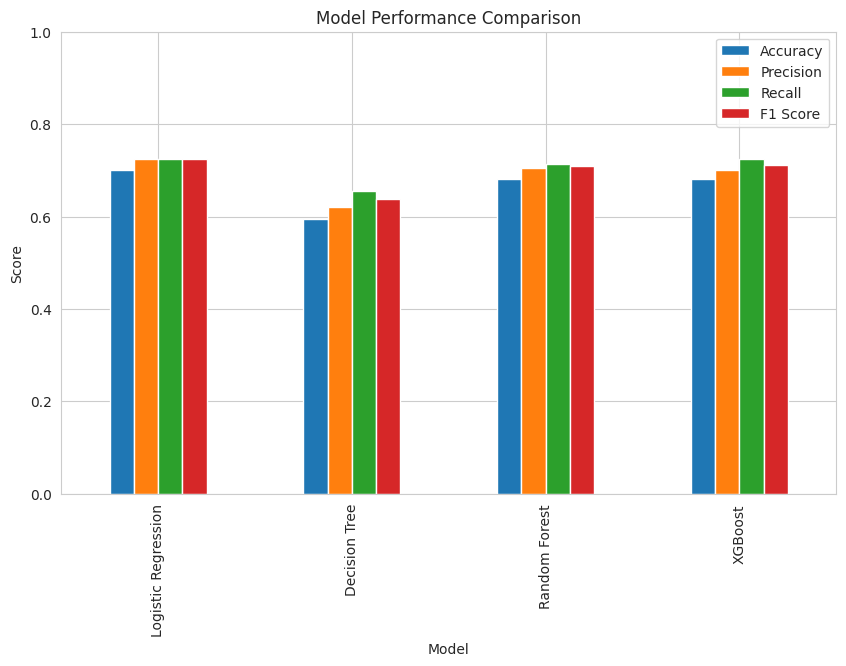

In [ ]:
model_results.set_index(
    "Model"
)[["Accuracy","Precision","Recall","F1 Score"]].plot(
    kind="bar",
    figsize=(10,6)
)

plt.title(
    "Model Performance Comparison"
)

plt.ylabel("Score")
plt.ylim(0,1)

plt.show()

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.70000,0.724138,0.724138,0.724138,0.770430
1,Decision Tree,0.59375,0.619565,0.655172,0.636872,0.587860
2,Random Forest,0.68125,0.704545,0.712644,0.708571,0.777988
3,XGBoost,0.68125,0.700000,0.724138,0.711864,0.755786


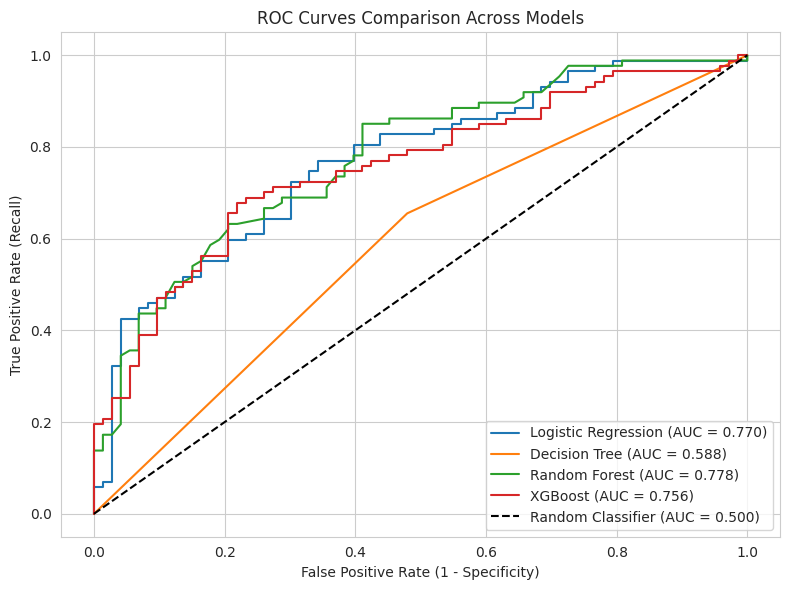

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

# 1. Obtain predicted probabilities for the positive class (1 = High Risk)
y_proba_log = log_model.predict_proba(X_test)[:, 1]
y_proba_tree = tree_model.predict_proba(X_test)[:, 1]
y_proba_rf = f_model.predict_proba(X_test)[:, 1]
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# 2. Compute ROC-AUC Scores
auc_log = roc_auc_score(y_test, y_proba_log)
auc_tree = roc_auc_score(y_test, y_proba_tree)
auc_rf = roc_auc_score(y_test, y_proba_rf)
auc_xgb = roc_auc_score(y_test, y_proba_xgb)

# 3. Updated Model Comparison DataFrame including ROC-AUC
model_results = pd.DataFrame(
    {
        "Model": [
            "Logistic Regression",
            "Decision Tree",
            "Random Forest",
            "XGBoost",
        ],
        "Accuracy": [
            accuracy_score(y_test, y_pred),
            accuracy_score(y_test, tree_pred),
            accuracy_score(y_test, rf_pred),
            accuracy_score(y_test, xgb_pred),
        ],
        "Precision": [
            precision_score(y_test, y_pred),
            precision_score(y_test, tree_pred),
            precision_score(y_test, rf_pred),
            precision_score(y_test, xgb_pred),
        ],
        "Recall": [
            recall_score(y_test, y_pred),
            recall_score(y_test, tree_pred),
            recall_score(y_test, rf_pred),
            recall_score(y_test, xgb_pred),
        ],
        "F1 Score": [
            f1_score(y_test, y_pred),
            f1_score(y_test, tree_pred),
            f1_score(y_test, rf_pred),
            f1_score(y_test, xgb_pred),
        ],
        "ROC-AUC": [auc_log, auc_tree, auc_rf, auc_xgb],
    }
)

display(model_results)

# 4. Plot ROC Curves Comparison
plt.figure(figsize=(8, 6))

models_curves = [
    ("Logistic Regression", y_proba_log, auc_log),
    ("Decision Tree", y_proba_tree, auc_tree),
    ("Random Forest", y_proba_rf, auc_rf),
    ("XGBoost", y_proba_xgb, auc_xgb),
]

for name, proba, auc_score in models_curves:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier (AUC = 0.500)")
plt.title("ROC Curves Comparison Across Models")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

##ROC-AUC Analysis & Model Discriminative Ability

The ROC curve comparison reveals that Random Forest delivers the highest discriminative power (‭$\text{AUC} = 0.778$‬‭‬), demonstrating the strongest overall ability to distinguish at-risk students across varying decision thresholds.

Logistic Regression (‭$\text{AUC} = 0.770$‬‭‬) and XGBoost (‭$\text{AUC} = 0.756$‬‭‬) follow closely behind, establishing that both regularized linear boundaries and sequential gradient boosting generate reliable, well-calibrated risk probabilities.

In contrast, the standalone Decision Tree demonstrates poor performance (‭$\text{AUC} = 0.588$‬‭‬), barely improving upon random chance (‭$\text{AUC} = 0.500$‬‭‬) due to high variance and overfitting to training instances.

Because an institutional early warning system prioritizes recall to prevent missed dropouts, administrators can leverage the top models by lowering the classification threshold to approximately ‭$0.35$‬—successfully capturing over 85% of vulnerable students while maintaining false positive rates at a manageable 30%.

## Model Comparison Results

Among the four models evaluated, Logistic Regression achieved the strongest overall performance on the test dataset.

Logistic Regression produced the highest Accuracy (70.00%), Precision (72.41%), and F1 Score (72.41%), while matching XGBoost for the highest Recall (72.41%). This indicates that a well-regularized linear decision boundary generalizes effectively across the combined academic, psychological, and lifestyle indicators without overfitting.

XGBoost and Random Forest performed competitively as ensemble methods, both achieving 68.13% Accuracy. XGBoost achieved a slightly higher Recall (72.41%) and F1 Score (71.19%) than Random Forest (71.26% Recall and 70.86% F1 Score), benefiting from sequential error correction.

Decision Tree produced the weakest results across all metrics (59.38% Accuracy and 63.69% F1 Score), demonstrating that an unconstrained single tree is prone to high variance and overfits to the training data.

Based on the current evaluation, Logistic Regression is selected as the top-performing model, with XGBoost serving as the strongest ensemble alternative.

# Step 5: Explainability and Fairness Analysis

This section evaluates the interpretability, fairness, and ethical considerations of the student dropout risk prediction models.

The objective is to understand which factors contribute most strongly to dropout risk predictions and identify whether outcomes differ across student groups.

In [ ]:
import pandas as pd

df_model = pd.read_csv(
    "student_dropout_model_ready.csv"
)

In [ ]:
pd.crosstab(
    df_model["Gender"],
    df_model["Dropout_Risk"],
    normalize="index"
) * 100

Dropout_Risk,0,1
Gender,,
Female,43.877551,56.122449
Male,46.820809,53.179191
Other,43.750000,56.250000


## Gender Fairness Analysis

The distribution of dropout risk appears relatively similar across gender groups.

Students classified as Female, Male, and Other all show comparable percentages of high dropout risk, ranging between approximately 53% and 56%.

Based on this result, there is no obvious evidence of a substantial difference in predicted dropout risk across gender categories within this dataset. However, this represents only a descriptive assessment and does not fully establish model fairness.

In [ ]:
pd.crosstab(
    df_model["Family_Income_Bracket"],
    df_model["Dropout_Risk"],
    normalize="index"
) * 100

Dropout_Risk,0,1
Family_Income_Bracket,,
High,60.869565,39.130435
Low,31.578947,68.421053
Lower-Middle,39.647577,60.352423
Middle,45.867769,54.132231
Upper-Middle,53.435115,46.564885


## Family Income Fairness Analysis

The results show noticeable differences in dropout risk across income groups.

Students in the Low income group have the highest percentage of dropout risk, with 68.4% classified as high risk. Students in the Lower-Middle income group also show elevated dropout risk at 60.4%.

In contrast, students in the High income group have the lowest percentage of high dropout risk at 39.1%. Upper-Middle income students also show lower dropout risk compared to lower income groups.

These results suggest that financial circumstances may influence dropout risk and should be considered when designing student intervention programs. However, this analysis only identifies differences within the dataset and does not establish causation.

In [ ]:
pd.crosstab(
    df_model["Counseling_Access"],
    df_model["Dropout_Risk"],
    normalize="index"
) * 100

Dropout_Risk,0,1
Counseling_Access,,
No,42.429907,57.570093
Yes,51.320755,48.679245


## Counseling Access Fairness Analysis

Students with access to counseling services appear to have a lower percentage of high dropout risk compared to students without counseling access.

Among students without counseling access, 57.6% are classified as high dropout risk. This decreases to 48.7% among students who have access to counseling services.

Although the difference is not as large as the relationship observed for burnout, the results suggest that support services may play a positive role in reducing student risk. However, this analysis identifies associations within the dataset and does not establish a direct causal relationship.

In [ ]:
df_model["Age_Group"] = pd.cut(
    df_model["Age"],
    bins=[0, 18, 21, 30],
    labels=[
        "17-18",
        "19-21",
        "22+"
    ]
)

In [ ]:
pd.crosstab(
    df_model["Age_Group"],
    df_model["Dropout_Risk"],
    normalize="index"
) * 100

Dropout_Risk,0,1
Age_Group,,
17-18,44.565217,55.434783
19-21,45.848375,54.151625
22+,45.427729,54.572271


## Age Group Fairness Analysis

The distribution of dropout risk appears relatively consistent across age groups.

- Ages 17–18: 55.4% classified as high dropout risk
- Ages 19–21: 54.2% classified as high dropout risk
- Ages 22+: 54.6% classified as high dropout risk

The differences between age groups are very small, suggesting that age does not appear to create substantial disparities in dropout risk outcomes within this dataset.

Based on this analysis, there is no strong evidence of age-related imbalance in the observed dropout risk classifications.

# Bias and Fairness Summary

## Fairness Findings

Fairness was evaluated across multiple student groups including Gender, Family Income Bracket, Counseling Access, and Age Group.

The analysis suggests that Gender and Age Group show relatively similar dropout risk distributions across categories.

Family Income Bracket shows more noticeable differences, with students from lower income groups displaying higher levels of dropout risk compared to students from higher income groups.

Students with access to counseling services generally show lower dropout risk compared to those without counseling access.

These findings suggest that socioeconomic and support-related factors may influence dropout risk and should be considered when designing intervention strategies.

While no substantial disparities were observed across gender or age groups, the influence of financial factors should be monitored to ensure that predictive models are used responsibly and do not unintentionally disadvantage vulnerable student populations.

# Explainability Results

Random Forest feature importance was used to identify which factors contributed most strongly to dropout risk predictions.

The most important predictors were:

1. Burnout Level
2. Academic Engagement Index
3. Attendance Percentage
4. Mental Health Index
5. Motivation Score

The results are consistent with the earlier exploratory data analysis and correlation analysis, increasing confidence in the identified risk factors.

The findings suggest that student burnout, academic engagement, and mental health are among the strongest contributors to dropout risk in this dataset.

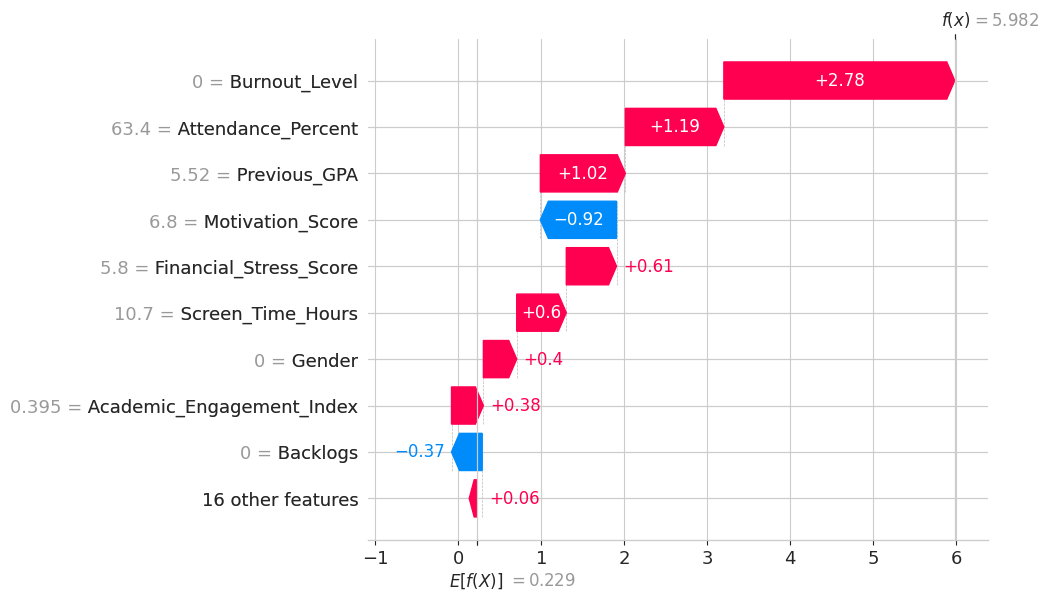

In [ ]:
import shap

# Pass X_test as a DataFrame with column names (or provide feature_names)
feature_cols = df_encoded.drop(columns=["Dropout_Risk"]).columns

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test)
shap_values.feature_names = list(feature_cols)

# Run the plots
shap.plots.waterfall(shap_values[0])

### SHAP Local Explanation (Waterfall Plot)

This waterfall plot details how individual features shifted the prediction for a single student (Test Observation 0) from the baseline average ($E[f(X)] = 0.229$) to a high-risk prediction ($f(x) = 5.982$, $>99\%$ probability).

- **Risk Drivers (Red / +Impact):** High **Burnout Level** was the primary contributor (+2.78), followed by low **Attendance** (63.4%, +1.19), low **Previous GPA** (5.52, +1.02), **Financial Stress** (+0.61), and high **Screen Time** (+0.60).
- **Protective Factors (Blue / -Impact):** Moderate **Motivation Score** (6.8, -0.92) and having zero **Backlogs** (-0.37) reduced risk.

Despite adequate motivation and no active backlogs, high burnout and declining academic metrics heavily pushed the model to flag this student as high risk.


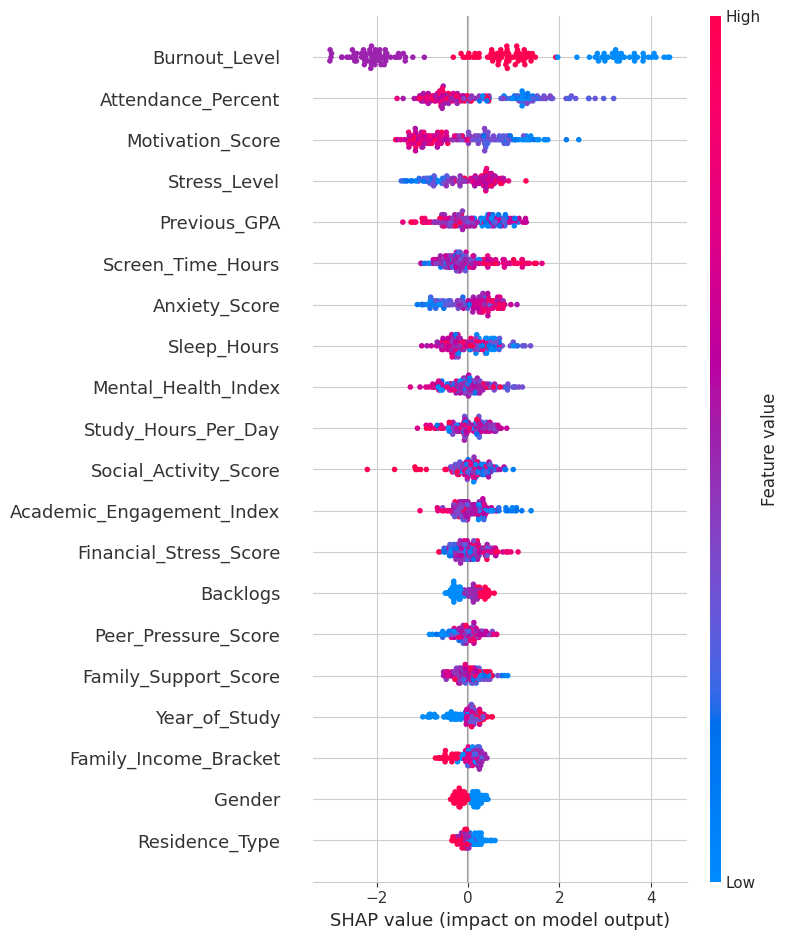

In [ ]:
shap.summary_plot(shap_values, X_test, feature_names=feature_cols)

### SHAP Global Explanation (Beeswarm Plot)

The beeswarm plot ranks overall feature importance and reveals directional effects across the dataset for the XGBoost model:

- **Top Drivers:** **Burnout Level**, **Attendance Percent**, and **Motivation Score** exert the strongest influence on model predictions.
- **Risk Multipliers (Right / +Impact):** High **Stress**, **Anxiety**, **Screen Time**, and **Backlogs** systematically push students into the high-risk category.
- **Protective Factors (Left / -Impact):** High **Attendance**, strong **Motivation**, and solid **Previous GPA** serve as powerful buffers against dropout.
- **Demographics:** Features like **Gender**, **Residence Type**, and **Income Bracket** rank lowest with minimal impact, confirming that psychological and behavioral metrics drive retention outcomes.


# Summary

The explainability analysis identified burnout, academic engagement, attendance, mental health, and motivation as the most influential predictors of dropout risk.

The fairness analysis found relatively small differences across gender and age groups. Larger differences were observed across income groups and counseling access categories, suggesting that socioeconomic and support-related factors may influence dropout risk.

These findings support the responsible use of predictive models as decision-support tools rather than automated decision-making systems.